# MSCS 634 – Project Deliverable 1
## Data Collection, Cleaning, and Exploration — Telco Customer Churn

**Student Name:** Sai Sravani P
**Course:** Advanced Big Data and Data Mining (MSCS 634)
**Date:** Nov 1 2026
**Deliverable:** 1 of 4 — Data Collection, Cleaning, and Exploratory Data Analysis 

### Objective
Select a real-world dataset, prepare it for data mining by cleaning it (missing values, duplicates, inconsistent
data, noisy data), and explore it with visualizations to find patterns that will guide the regression,
classification, clustering, and association-rule work in Deliverables 2–4.



## 1. Dataset Selection and Justification

**Dataset:** IBM *Telco Customer Churn* (IBM sample data set, widely mirrored on Kaggle as `blastchar/telco-customer-churn`).
**Source used here:** IBM's public GitHub repository (`IBM/telco-customer-churn-on-icp4d`

The data describes **7,043 customers** of a fictional home-phone and internet provider in California, with **21 attributes**
per customer covering demographics, account details, subscribed services, billing, and whether the customer left
(churned) in the last month.

### Why this dataset is appropriate
1. **Meets the size criteria comfortably** – 7,043 records (≫ 500) and 21 attributes (≫ 8–10).
2. **Real business problem** – customer churn is one of the most costly problems in subscription businesses; acquiring a new customer typically costs far more than retaining one. Insights translate directly into retention actions.
3. **Mixed data types** – 3 numeric attributes, 1 binary integer, and 16 categorical attributes. This exercises a full range of preprocessing techniques (type conversion, encoding, scaling).
4. **Contains genuine data-quality issues** – hidden missing values stored as blank strings, a numeric column stored as text, inconsistent coding of a binary field, and redundant category levels. These make the cleaning phase meaningful rather than cosmetic.
5. **Supports every later deliverable:**
   | Deliverable | Technique | Natural task on this data |
   |---|---|---|
   | 2 | Regression | Predict `MonthlyCharges` (or `TotalCharges` / customer lifetime value) from services and contract |
   | 3 | Classification | Predict `Churn` (Yes/No) |
   | 3 | Clustering | Segment customers by tenure, spend and service bundle |
   | 4 | Association rules | Find service combinations that co-occur with churn (e.g. `{Month-to-month, Fiber optic, No TechSupport} → {Churn=Yes}`) |

### Attribute dictionary
| Attribute | Type | Description |
|---|---|---|
| `customerID` | ID (text) | Unique customer identifier (not a predictive feature) |
| `gender` | Categorical | Male / Female |
| `SeniorCitizen` | Binary (0/1) | Whether the customer is 65 or older |
| `Partner` | Binary (Yes/No) | Whether the customer has a partner |
| `Dependents` | Binary (Yes/No) | Whether the customer has dependents (children, parents, etc.) |
| `tenure` | Numeric (months) | Number of months the customer has stayed with the company (0–72) |
| `PhoneService` | Binary | Has home phone service |
| `MultipleLines` | Categorical | Yes / No / No phone service |
| `InternetService` | Categorical | DSL / Fiber optic / No |
| `OnlineSecurity` | Categorical | Yes / No / No internet service |
| `OnlineBackup` | Categorical | Yes / No / No internet service |
| `DeviceProtection` | Categorical | Yes / No / No internet service |
| `TechSupport` | Categorical | Yes / No / No internet service |
| `StreamingTV` | Categorical | Yes / No / No internet service |
| `StreamingMovies` | Categorical | Yes / No / No internet service |
| `Contract` | Categorical | Month-to-month / One year / Two year |
| `PaperlessBilling` | Binary | Uses paperless billing |
| `PaymentMethod` | Categorical | Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic) |
| `MonthlyCharges` | Numeric ($) | Current monthly amount charged |
| `TotalCharges` | Numeric ($) | Total amount charged over the customer's lifetime (**stored as text in the raw file**) |
| `Churn` | Binary – **target** | Whether the customer left within the last month |

## 2. Environment Setup and Data Loading

In [1]:
# ---------------------------------------------------------------
# Core libraries
# ---------------------------------------------------------------
import os
import warnings

import numpy as np                 # numerical operations
import pandas as pd                # tabular data handling
import matplotlib.pyplot as plt    # base plotting
import seaborn as sns              # statistical visualisation
from scipy import stats            # statistical tests (chi-square, point-biserial, z-score)

warnings.filterwarnings("ignore")  # keep the notebook output readable

# ---------------------------------------------------------------
# Displaying & plotting configuration
# ---------------------------------------------------------------
pd.set_option("display.max_columns", 50)   # show every column of the 21-column table
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# Consistent colours for the target variable throughout the notebook
CHURN_PALETTE = {"No": "#4C72B0", "Yes": "#DD8452"}

# Folder where every figure is also saved as PNG (used in the README)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Save the current matplotlib figure to figures/<name>.png with tight borders.
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | seaborn 0.13.2


In [2]:
# ---------------------------------------------------------------
# Loading the raw dataset
# ---------------------------------------------------------------
RAW_PATH = "data/Telco-Customer-Churn.csv"
RAW_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
           "master/data/Telco-Customer-Churn.csv")

if not os.path.exists(RAW_PATH):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(RAW_URL).to_csv(RAW_PATH, index=False)

df_raw = pd.read_csv(RAW_PATH)

# Working on a copy so the raw data remains available for before/after comparisons
df = df_raw.copy()
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Inspecting the Structure of the Data
We first look at data types, non-null counts, summary statistics, and the number of distinct values per column.
This tells us what each column *should* look like, which is the basis for spotting anything that doesn't.

In [3]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Summary statistics for the columns pandas recognised as numeric
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [5]:
# Number of distinct values per column, plus a sample of the values.
# Low cardinality => categorical; very high cardinality => ID or continuous.
cardinality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "sample_values": [df[c].unique()[:4].tolist() for c in df.columns],
})
cardinality

,dtype,n_unique,sample_values
customerID,str,7043,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,"[Female, Male]"
SeniorCitizen,int64,2,"[0, 1]"
Partner,str,2,"[Yes, No]"
Dependents,str,2,"[No, Yes]"
tenure,int64,73,"[1, 34, 2, 45]"
PhoneService,str,2,"[No, Yes]"
MultipleLines,str,3,"[No phone service, No, Yes]"
InternetService,str,3,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,"[No, Yes, No internet service]"


**Observations from the structural inspection**

* `TotalCharges` was read as **text**, even though it is a dollar amount. This means at least one value cannot be parsed as a number — a red flag for hidden missing or malformed data.
* `SeniorCitizen` is coded **0/1**, while every other yes/no column (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`) uses **"Yes"/"No"**. This is an encoding inconsistency.
* `customerID` has 7,043 unique values for 7,043 rows — it is a pure identifier and should not be used as a feature.
* `tenure` ranges from **0** to 72 months. A tenure of 0 means the customer has just joined, which will matter for `TotalCharges`.
* Most columns are low-cardinality categoricals (2–4 levels).

## 4. Data-Quality Audit
Before changing anything, we systematically check for each class of problem named in the assignment:
**missing values, duplicates, inconsistent data, and noisy data.** Auditing first and cleaning second keeps every
change traceable to a specific, documented finding.

### 4.1 Missing values (explicit and hidden)

In [6]:
# (a) Explicit missing values: NaN / None as recognised by pandas
explicit_missing = df.isna().sum()
print("Explicit NaN values per column (non-zero only):")
print(explicit_missing[explicit_missing > 0] if explicit_missing.sum() else "  none found")

# (b) Hidden missing values: empty or whitespace-only strings in text columns.
#     pandas does NOT treat " " as missing, so isna() alone would miss these.
text_cols = df.select_dtypes(exclude="number").columns
hidden_missing = {c: int(df[c].astype(str).str.strip().eq("").sum()) for c in text_cols}
hidden_missing = {c: n for c, n in hidden_missing.items() if n > 0}
print("\nBlank / whitespace-only strings per column:", hidden_missing)

Explicit NaN values per column (non-zero only):
  none found

Blank / whitespace-only strings per column: {'TotalCharges': 11}


In [7]:
# Inspect the rows with a blank TotalCharges to understand WHY the value is missing
blank_tc = df[df["TotalCharges"].astype(str).str.strip() == ""]
blank_tc[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [8]:
# Is "blank TotalCharges" exactly the same set of customers as "tenure == 0"?
print("Rows with tenure == 0          :", (df["tenure"] == 0).sum())
print("Rows with blank TotalCharges   :", len(blank_tc))
print("Every blank row has tenure == 0:", (blank_tc["tenure"] == 0).all())

Rows with tenure == 0          : 11
Rows with blank TotalCharges   : 11
Every blank row has tenure == 0: True


**Finding:** `df.isna()` reports **zero** missing values, which would lead a careless analysis to conclude the data is complete.
In reality, **11 rows** have `TotalCharges` stored as a blank string (`" "`). All 11 are customers with `tenure = 0`,
and they are the **only** customers with `tenure = 0`. These customers signed up but have not yet completed a billing
cycle, so no lifetime charge has accumulated. The values are **structurally missing** (missing for a known reason),
not missing at random.

### 4.2 Duplicates
Duplicates are checked at three levels, because each one means something different.

In [9]:
# Level 1 – fully identical rows (including customerID)
print("Exact duplicate rows                       :", df.duplicated().sum())

# Level 2 – repeated customer IDs (the same customer recorded twice)
print("Duplicate customerID values                :", df["customerID"].duplicated().sum())

# Level 3 – identical attribute profiles under DIFFERENT customer IDs
feature_cols = [c for c in df.columns if c != "customerID"]
profile_dups = df[df.duplicated(subset=feature_cols, keep=False)]
print("Rows sharing an identical profile (diff ID):", len(profile_dups))

Exact duplicate rows                       : 0
Duplicate customerID values                : 0
Rows sharing an identical profile (diff ID): 42


In [10]:
# What do these profile-level duplicates look like?
profile_dups.sort_values(feature_cols)[["customerID", "tenure", "PhoneService", "InternetService",
                                        "Contract", "MonthlyCharges", "TotalCharges", "Churn"]].head(10)

,customerID,tenure,PhoneService,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,1,Yes,Fiber optic,Month-to-month,69.20,69.2,Yes
6764,7660-HDPJV,1,Yes,Fiber optic,Month-to-month,69.20,69.2,Yes
4495,4702-IOQDC,1,Yes,Fiber optic,Month-to-month,70.10,70.1,Yes
6267,0328-GRPMV,1,Yes,Fiber optic,Month-to-month,70.10,70.1,Yes
5522,2619-WFQWU,1,Yes,Fiber optic,Month-to-month,70.15,70.15,Yes
5759,9985-MWVIX,1,Yes,Fiber optic,Month-to-month,70.15,70.15,Yes
542,2866-IKBTM,1,Yes,No,Month-to-month,19.55,19.55,No
1491,8605-ITULD,1,Yes,No,Month-to-month,19.55,19.55,No
5170,7721-DVEKZ,1,Yes,No,Month-to-month,19.65,19.65,No
6774,0970-QXPXW,1,Yes,No,Month-to-month,19.65,19.65,No


**Finding:** there are **no exact duplicate rows** and **no repeated customer IDs**. There are 42 rows (22 extra copies)
whose attributes are identical to another row but whose `customerID` differs. **All 42 are brand-new
(tenure = 1), month-to-month customers**, mostly on the simplest bundles (26 with no internet service at ~\$20/month,
12 fiber, 4 DSL). For a 1-month customer, `TotalCharges` simply equals `MonthlyCharges`, so the two numeric columns add no
extra uniqueness. With only 2–4 levels per categorical column and a 1-month tenure, two different people having the same
profile is entirely expected. These are **legitimate distinct customers**, not data-entry duplicates, so they will be
**kept** (removing them would wrongly under-represent the cheapest customer segment).

### 4.3 Inconsistent data

In [11]:
# (a) Leading/trailing whitespace or inconsistent capitalisation in category labels.
#     We compare the raw labels to a stripped, lower-cased version: if the counts differ,
#     two spellings of the same label exist (e.g. "Yes" vs "yes ").
cat_cols = [c for c in df.select_dtypes(exclude="number").columns
            if c not in ("customerID", "TotalCharges")]
for c in cat_cols:
    raw_levels = df[c].nunique()
    norm_levels = df[c].astype(str).str.strip().str.lower().nunique()
    flag = "  <-- inconsistent" if raw_levels != norm_levels else ""
    print(f"{c:18s} levels={raw_levels}  normalised={norm_levels}{flag}")

gender             levels=2  normalised=2
Partner            levels=2  normalised=2
Dependents         levels=2  normalised=2
PhoneService       levels=2  normalised=2
MultipleLines      levels=3  normalised=3
InternetService    levels=3  normalised=3
OnlineSecurity     levels=3  normalised=3
OnlineBackup       levels=3  normalised=3
DeviceProtection   levels=3  normalised=3
TechSupport        levels=3  normalised=3
StreamingTV        levels=3  normalised=3
StreamingMovies    levels=3  normalised=3
Contract           levels=3  normalised=3
PaperlessBilling   levels=2  normalised=2
PaymentMethod      levels=4  normalised=4
Churn              levels=2  normalised=2


In [12]:
# (b) Encoding inconsistency: SeniorCitizen uses 0/1 while other binary columns use Yes/No
binary_text_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
print("SeniorCitizen values :", sorted(df["SeniorCitizen"].unique()))
for c in binary_text_cols:
    print(f"{c:20s} values :", sorted(df[c].unique()))

SeniorCitizen values : [np.int64(0), np.int64(1)]
Partner              values : ['No', 'Yes']
Dependents           values : ['No', 'Yes']
PhoneService         values : ['No', 'Yes']
PaperlessBilling     values : ['No', 'Yes']
Churn                values : ['No', 'Yes']


In [13]:
# (c) Redundant category levels: "No internet service" / "No phone service".
#     If these levels carry no information beyond InternetService / PhoneService,
#     they are redundant and inflate the number of categories.
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]

no_internet = df["InternetService"] == "No"
for c in internet_addons:
    match = (df[c] == "No internet service").eq(no_internet).all()
    print(f"{c:17s}: 'No internet service' <=> InternetService == 'No' ? {match}")

no_phone = df["PhoneService"] == "No"
print(f"{'MultipleLines':17s}: 'No phone service'    <=> PhoneService == 'No'    ?",
      (df["MultipleLines"] == "No phone service").eq(no_phone).all())

OnlineSecurity   : 'No internet service' <=> InternetService == 'No' ? True
OnlineBackup     : 'No internet service' <=> InternetService == 'No' ? True
DeviceProtection : 'No internet service' <=> InternetService == 'No' ? True
TechSupport      : 'No internet service' <=> InternetService == 'No' ? True
StreamingTV      : 'No internet service' <=> InternetService == 'No' ? True
StreamingMovies  : 'No internet service' <=> InternetService == 'No' ? True
MultipleLines    : 'No phone service'    <=> PhoneService == 'No'    ? True


In [14]:
# (d) Domain / range checks on numeric fields
print("tenure range         :", df["tenure"].min(), "-", df["tenure"].max(), "months (valid: 0-72)")
print("MonthlyCharges range : $", df["MonthlyCharges"].min(), "- $", df["MonthlyCharges"].max())
print("Negative values      :", (df[["tenure", "MonthlyCharges"]] < 0).sum().sum())

tenure range         : 0 - 72 months (valid: 0-72)
MonthlyCharges range : $ 18.25 - $ 118.75
Negative values      : 0


**Findings on consistency**

| Issue | Evidence | Planned fix |
|---|---|---|
| No whitespace / capitalisation variants | normalised level counts equal raw counts for every column | none needed (a strip step is still applied defensively) |
| `SeniorCitizen` coded 0/1, other binaries coded Yes/No | value check above | recode to Yes/No so all binary flags share one convention |
| `"No internet service"` in 6 add-on columns and `"No phone service"` in `MultipleLines` | each is **perfectly** equivalent to `InternetService == "No"` / `PhoneService == "No"` | collapse to `"No"` – the information is already held in `InternetService` / `PhoneService` |
| `TotalCharges` stored as text | dtype `object/str` | convert to `float` |
| Numeric ranges | all within valid domain, no negatives | none needed |

## 5. Data Cleaning
Each step below fixes one issue identified in the audit. A running log records what was changed so the
README and the reader can see the full cleaning trail.

In [15]:
cleaning_log = []   # list of (step, rows/cells affected, rationale)

# ---------------------------------------------------------------
# Step 1 – Strip stray whitespace from every text column (defensive)
# ---------------------------------------------------------------
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype(str).str.strip()
cleaning_log.append(("Strip whitespace in text columns", "0 labels changed",
                     "Defensive: guarantees 'Yes' and 'Yes ' can never become separate categories"))

# ---------------------------------------------------------------
# Step 2 – Convert TotalCharges from text to numeric.
# errors="coerce" turns the 11 blank strings into NaN, making them visible to pandas.
# ---------------------------------------------------------------
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace("", np.nan), errors="coerce")
n_tc_missing = int(df["TotalCharges"].isna().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype, "| NaN after conversion:", n_tc_missing)
cleaning_log.append(("Convert TotalCharges text -> float", f"{len(df):,} cells",
                     "A monetary amount must be numeric for statistics and modelling"))

TotalCharges dtype: float64 | NaN after conversion: 11


#### Step 3 – Handling the 11 missing `TotalCharges` values: why impute with 0?
Three options were considered:

| Option | Effect | Verdict |
|---|---|---|
| **Drop the 11 rows** | Loses 0.16% of data – small, but removes *every* brand-new customer, a segment that matters for churn | Rejected – introduces selection bias |
| **Mean / median imputation** | Would assign these customers ~\$1,400 of lifetime charges they have never paid | Rejected – factually wrong, contradicts `tenure = 0` |
| **Impute 0 (domain-based)** | `TotalCharges ≈ tenure × MonthlyCharges = 0 × MonthlyCharges = 0` | **Chosen** – logically correct and consistent with the rest of the data |

Because the missingness is fully explained by `tenure = 0`, a **rule-based imputation** is more accurate than any
statistical estimate.

In [16]:
# ---------------------------------------------------------------
# Step 3 – Domain-based imputation: no completed billing cycle => no lifetime charges yet
# ---------------------------------------------------------------
mask_new = df["TotalCharges"].isna() & (df["tenure"] == 0)
df.loc[mask_new, "TotalCharges"] = 0.0
cleaning_log.append(("Impute missing TotalCharges = 0 (tenure == 0)", f"{int(mask_new.sum())} rows",
                     "Customers who have not finished a billing cycle have accumulated $0"))
print("Remaining missing values in the whole dataset:", int(df.isna().sum().sum()))

Remaining missing values in the whole dataset: 0


In [17]:
# ---------------------------------------------------------------
# Step 4 – Standardise binary encoding: SeniorCitizen 0/1 -> "No"/"Yes"
# ---------------------------------------------------------------
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
cleaning_log.append(("Recode SeniorCitizen 0/1 -> No/Yes", f"{len(df):,} cells",
                     "One consistent convention for every binary flag"))

# ---------------------------------------------------------------
# Step 5 – Collapse redundant "No internet service" / "No phone service" levels to "No".
# Verified in Section 4.3 that these levels are perfectly implied by
# InternetService == "No" and PhoneService == "No", so no information is lost.
# ---------------------------------------------------------------
n_changed = 0
for c in internet_addons:
    n_changed += (df[c] == "No internet service").sum()
    df[c] = df[c].replace("No internet service", "No")
n_changed += (df["MultipleLines"] == "No phone service").sum()
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")
cleaning_log.append(("Collapse 'No internet/phone service' -> 'No'", f"{int(n_changed):,} cells",
                     "Removes redundant levels; information is retained in InternetService/PhoneService"))

# ---------------------------------------------------------------
# Step 6 – Duplicates: verified none to remove (Section 4.2)
# ---------------------------------------------------------------
cleaning_log.append(("Duplicate check (rows, IDs, profiles)", "0 rows removed",
                     "No exact/ID duplicates; 22 profile duplicates are distinct new customers"))

# Confirm the result
for c in internet_addons + ["MultipleLines", "SeniorCitizen"]:
    print(f"{c:17s}", sorted(df[c].unique()))

OnlineSecurity    ['No', 'Yes']
OnlineBackup      ['No', 'Yes']
DeviceProtection  ['No', 'Yes']
TechSupport       ['No', 'Yes']
StreamingTV       ['No', 'Yes']
StreamingMovies   ['No', 'Yes']
MultipleLines     ['No', 'Yes']
SeniorCitizen     ['No', 'Yes']


In [19]:
# Cleaning summary table
pd.DataFrame(cleaning_log, columns=["Cleaning step", "Affected", "Rationale"])

,Cleaning step,Affected,Rationale
0,Strip whitespace in text columns,0 labels changed,Defensive: guarantees 'Yes' and 'Yes ' can nev...
1,Convert TotalCharges text -> float,"7,043 cells",A monetary amount must be numeric for statisti...
2,Impute missing TotalCharges = 0 (tenure == 0),11 rows,Customers who have not finished a billing cycl...
3,Recode SeniorCitizen 0/1 -> No/Yes,"7,043 cells",One consistent convention for every binary flag
4,Collapse 'No internet/phone service' -> 'No',"9,838 cells",Removes redundant levels; information is retai...
5,"Duplicate check (rows, IDs, profiles)",0 rows removed,No exact/ID duplicates; 22 profile duplicates ...
6,"Add ChurnFlag, TenureGroup, NumAddOnServices",3 new columns,Support churn-rate analysis and later feature ...


## 6. Noise and Outlier Analysis
Noise can appear as **statistical outliers** (values far from the rest) or as **logically implausible records**
(values that break a business rule). We check both.

### 6.1 Statistical outliers – IQR rule and z-scores

In [21]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

def iqr_outliers(series):
    # Count values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] (Tukey's fences).
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lo) | (series > hi)).sum()), lo, hi

rows = []
for c in num_cols:
    n_iqr, lo, hi = iqr_outliers(df[c])
    n_z = int((np.abs(stats.zscore(df[c])) > 3).sum())     # |z| > 3
    rows.append([c, df[c].min(), df[c].max(), round(lo, 2), round(hi, 2), n_iqr, n_z,
                 round(df[c].skew(), 3)])
pd.DataFrame(rows, columns=["feature", "min", "max", "IQR lower fence", "IQR upper fence",
                            "IQR outliers", "|z|>3 outliers", "skewness"])

,feature,min,max,IQR lower fence,IQR upper fence,IQR outliers,|z|>3 outliers,skewness
0,tenure,0.00,72.00,-60.00,124.00,0,0,0.240
1,MonthlyCharges,18.25,118.75,-46.02,171.38,0,0,-0.221
2,TotalCharges,0.00,8684.80,-4683.52,8868.67,0,0,0.963


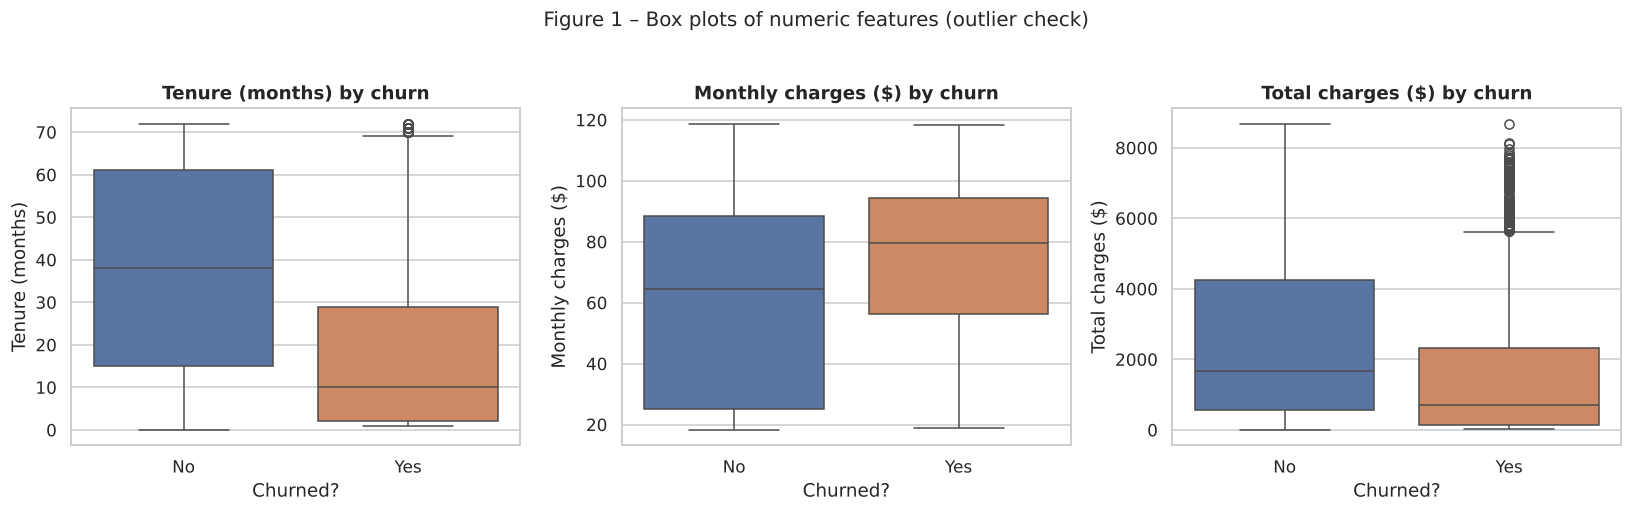

In [22]:
# Box plots make the (absence of) outliers visible, split by churn status
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
titles = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges ($)",
          "TotalCharges": "Total charges ($)"}
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, hue="Churn", palette=CHURN_PALETTE, legend=False, ax=ax)
    ax.set_title(f"{titles[c]} by churn")
    ax.set_xlabel("Churned?")
    ax.set_ylabel(titles[c])
plt.suptitle("Figure 1 – Box plots of numeric features (outlier check)", y=1.03, fontsize=13)
plt.tight_layout()
save_fig("fig01_boxplots_outliers")
plt.show()

**Interpretation:** neither Tukey's IQR fences nor the |z| > 3 rule flags a single value in the full dataset. All values lie within
plausible business ranges (tenure 0–72 months, monthly charges \$18–\$119). `TotalCharges` is strongly **right-skewed**
(skew ≈ 0.96), but this is a natural consequence of accumulating charges over time, not noise.

Within the churned group, a few long-tenure / high-total customers appear as dots beyond the whiskers. These are
*conditional* outliers (unusual for churners, normal for the population) — loyal customers who eventually left.
They are real and informative, so they are **kept**. *Implication for modelling:* no outlier removal is needed,
but the skew of `TotalCharges` suggests a log transform or a tree-based model in later deliverables.



## 7. Exploratory Data Analysis (EDA)

### 7.1 Target variable – how imbalanced is churn?

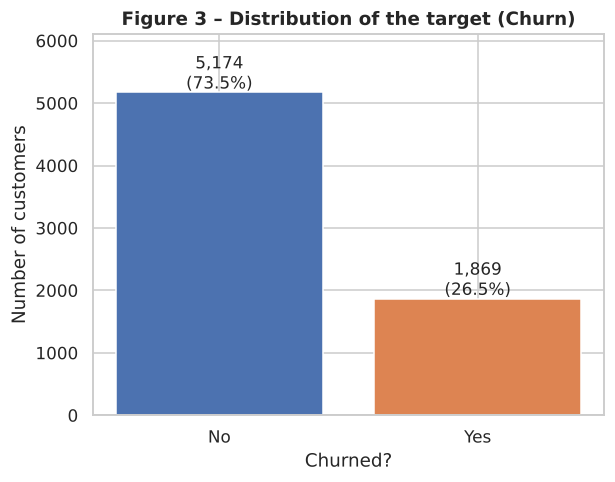

In [25]:
# Count and percentage of customers in each churn class
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(churn_counts.index, churn_counts.values,
              color=[CHURN_PALETTE[k] for k in churn_counts.index])
# Label each bar with its count and percentage
for bar, pct, n in zip(bars, churn_pct.values, churn_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 60,
            f"{n:,}\n({pct:.1f}%)", ha="center", fontsize=11)
ax.set_ylim(0, churn_counts.max() * 1.18)
ax.set_title("Figure 3 – Distribution of the target (Churn)")
ax.set_xlabel("Churned?")
ax.set_ylabel("Number of customers")
save_fig("fig03_target_distribution")
plt.show()

**Insight:** about **26.5%** of customers churned (≈ 1 in 4). The classes are **moderately imbalanced (≈ 2.8 : 1)**.
A model that always predicts "No churn" would already be 73.5% accurate, so **accuracy alone will be misleading**
in Deliverable 3; we will use stratified splits and report precision, recall, F1 and ROC-AUC, and consider
class weighting or SMOTE.

### 7.2 Distributions of numeric features by churn status

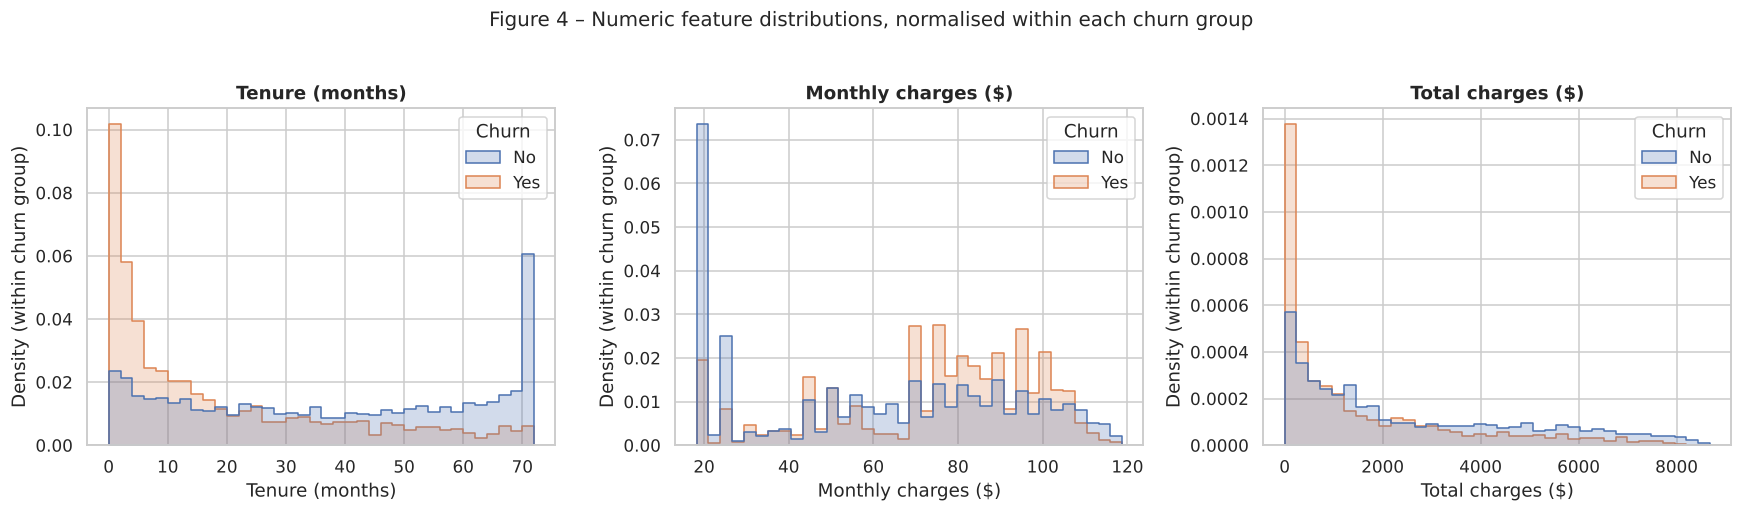

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", palette=CHURN_PALETTE, bins=36,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{titles[c]}")
    ax.set_xlabel(titles[c])
    ax.set_ylabel("Density (within churn group)")
plt.suptitle("Figure 4 – Numeric feature distributions, normalised within each churn group",
             y=1.03, fontsize=13)
plt.tight_layout()
save_fig("fig04_numeric_distributions")
plt.show()

# Group medians quantify what the plots show
df.groupby("Churn")[num_cols].median().round(2)

**Insights**
* **Tenure** is the clearest separator. Churners are concentrated in the first months (median **10 months** vs **38**
  for retained customers). Retained customers show a **bimodal** shape with a large spike at 70–72 months, i.e. a loyal
  long-term base.
* **MonthlyCharges:** churners are skewed toward **higher** monthly bills (median **\$79.65** vs **\$64.43**). The
  retained group has a large peak near **\$20**, which corresponds to phone-only customers.
* **TotalCharges** is *lower* for churners. This is not because they pay less per month but because they leave early,
  so this feature is largely a by-product of tenure (see the correlation analysis).

### 7.3 Churn rate across categorical features
For each categorical feature we plot the **churn rate per category**. The dashed line is the overall churn rate
(26.5%); bars well above it mark high-risk groups.

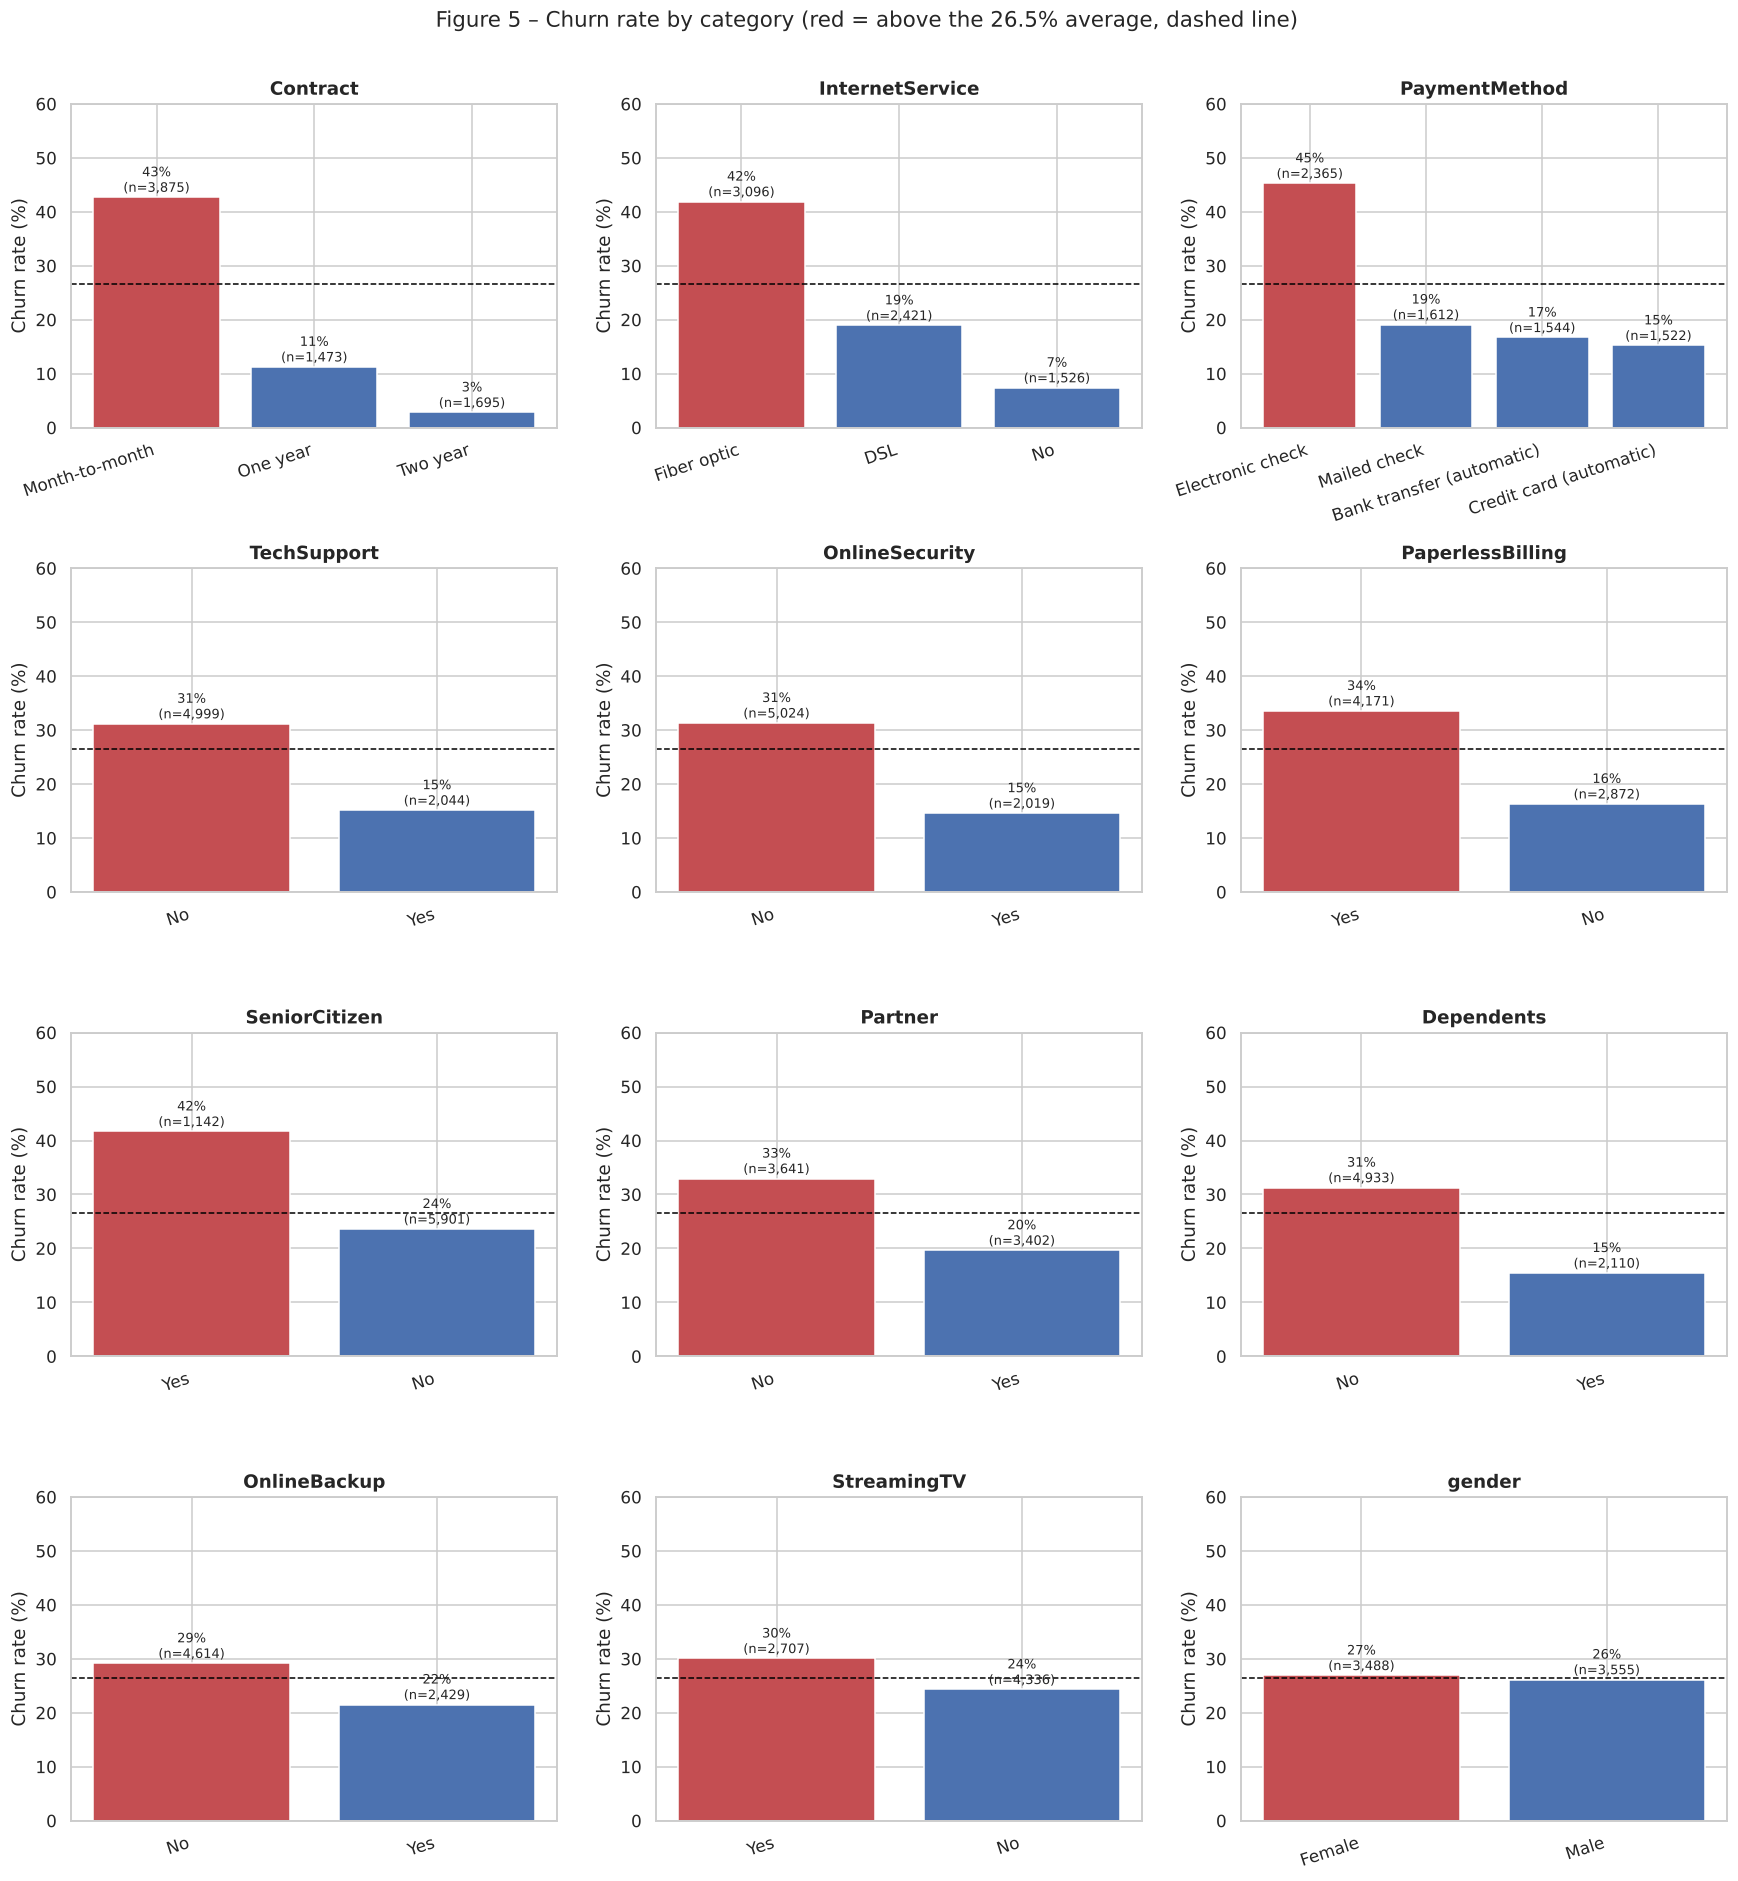

In [27]:
overall_rate = df["ChurnFlag"].mean()
plot_cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
             "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner",
             "Dependents", "OnlineBackup", "StreamingTV", "gender"]

fig, axes = plt.subplots(4, 3, figsize=(16, 17))
for ax, c in zip(axes.flat, plot_cats):
    rates = df.groupby(c, observed=True)["ChurnFlag"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    colors = ["#C44E52" if r > overall_rate else "#4C72B0" for r in rates["mean"]]
    ax.bar(rates.index.astype(str), rates["mean"] * 100, color=colors)
    ax.axhline(overall_rate * 100, color="black", linestyle="--", linewidth=1)
    for i, (r, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(i, r * 100 + 1, f"{r:.0%}\n(n={n:,})", ha="center", fontsize=8.5)
    ax.set_title(c)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=18)
    for label in ax.get_xticklabels():
        label.set_ha("right")
plt.suptitle("Figure 5 – Churn rate by category (red = above the 26.5% average, dashed line)",
             y=1.005, fontsize=14)
plt.tight_layout()
save_fig("fig05_churn_rate_by_category")
plt.show()

**Insights**
* **Contract type is the strongest categorical driver.** Month-to-month customers churn at **~43%**, versus **~11%**
  on one-year and **~3%** on two-year contracts — a 15× difference.
* **Fiber-optic internet customers churn at ~42%**, more than double DSL (~19%). Fiber is the premium (expensive)
  product, which points to a price or service-quality problem worth flagging to the business.
* **Electronic-check payers churn at ~45%**, compared with 15–19% for the other three methods. The automatic methods
  (bank transfer, credit card) have the lowest churn, consistent with lower friction to stay.
* **Protective add-ons reduce churn:** customers *without* `TechSupport` or `OnlineSecurity` churn at ~31% versus ~15%
  with them. (Before collapsing "No internet service" into "No", the *without* group churned at ~42%. The low-churn
  phone-only customers now sit in the "No" group, which dilutes this contrast. The effect is still clear, and
  `InternetService` keeps the information that separates the two groups.)
* **Senior citizens (~42%)**, customers **without partners (~33%)** or **dependents (~31%)**, and **paperless-billing** users
  (~34%) are also higher-risk.
* **Gender has virtually no effect** (26.9% vs 26.2%) and is a candidate for removal during feature selection.
  `StreamingTV` actually shows slightly *higher* churn for subscribers (30% vs 24%), probably because streaming customers
  are mostly on expensive fiber plans.

### 7.4 Tenure as the dominant pattern

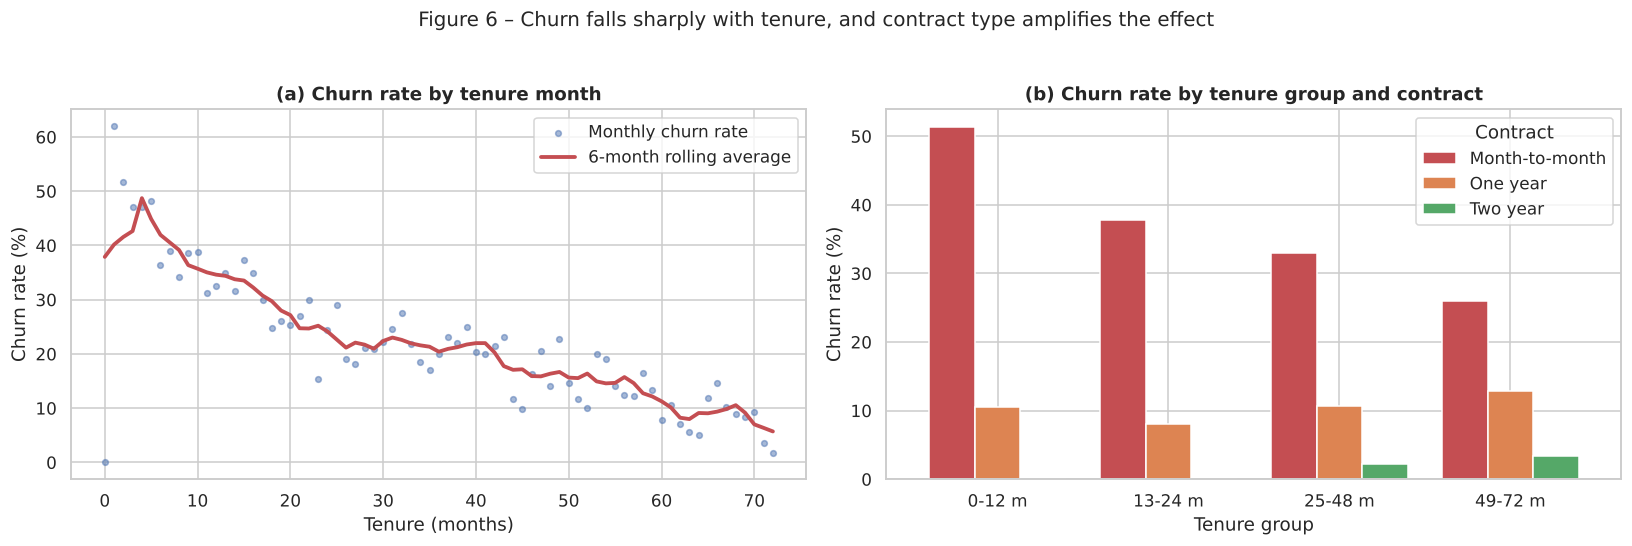

Churn rate by tenure group:
TenureGroup
0-12 m     47.4
13-24 m    28.7
25-48 m    20.4
49-72 m     9.5


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# (a) Churn rate for every tenure month, with a rolling average to smooth noise
by_month = df.groupby("tenure")["ChurnFlag"].mean() * 100
axes[0].scatter(by_month.index, by_month.values, s=14, alpha=0.5, color="#4C72B0", label="Monthly churn rate")
axes[0].plot(by_month.rolling(6, center=True, min_periods=1).mean(), color="#C44E52",
             linewidth=2.5, label="6-month rolling average")
axes[0].set_title("(a) Churn rate by tenure month")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Churn rate (%)")
axes[0].legend()

# (b) Churn rate by tenure group, split by contract type (interaction effect)
ct = df.groupby(["TenureGroup", "Contract"], observed=True)["ChurnFlag"].mean().unstack() * 100
ct.plot(kind="bar", ax=axes[1], color=["#C44E52", "#DD8452", "#55A868"], width=0.8)
axes[1].set_title("(b) Churn rate by tenure group and contract")
axes[1].set_xlabel("Tenure group")
axes[1].set_ylabel("Churn rate (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Contract")

plt.suptitle("Figure 6 – Churn falls sharply with tenure, and contract type amplifies the effect",
             y=1.03, fontsize=13)
plt.tight_layout()
save_fig("fig06_tenure_contract")
plt.show()

print("Churn rate by tenure group:")
print((df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean() * 100).round(1).to_string())

**Insights**
* Churn is **highest in the first year (~47%)** and drops steadily: ~29% (year 2), ~20% (years 3–4), and ~10% after 4 years.
  The relationship is clearly **non-linear**: very steep early, then flattening. This favours tree-based models or
  binned / log-transformed tenure features over a single linear term.
* There is a strong **interaction** between tenure and contract: even new customers churn far less on long contracts,
  and month-to-month customers remain risky at every tenure level (51% in year 1, still 26% after year 4).
  **Not one** of the 158 two-year-contract customers in their first 24 months churned (0%), which is why those bars are
  absent. Models that capture interactions
  (decision trees, random forests, gradient boosting) should therefore perform well.

### 7.5 Pricing: monthly charges by internet service

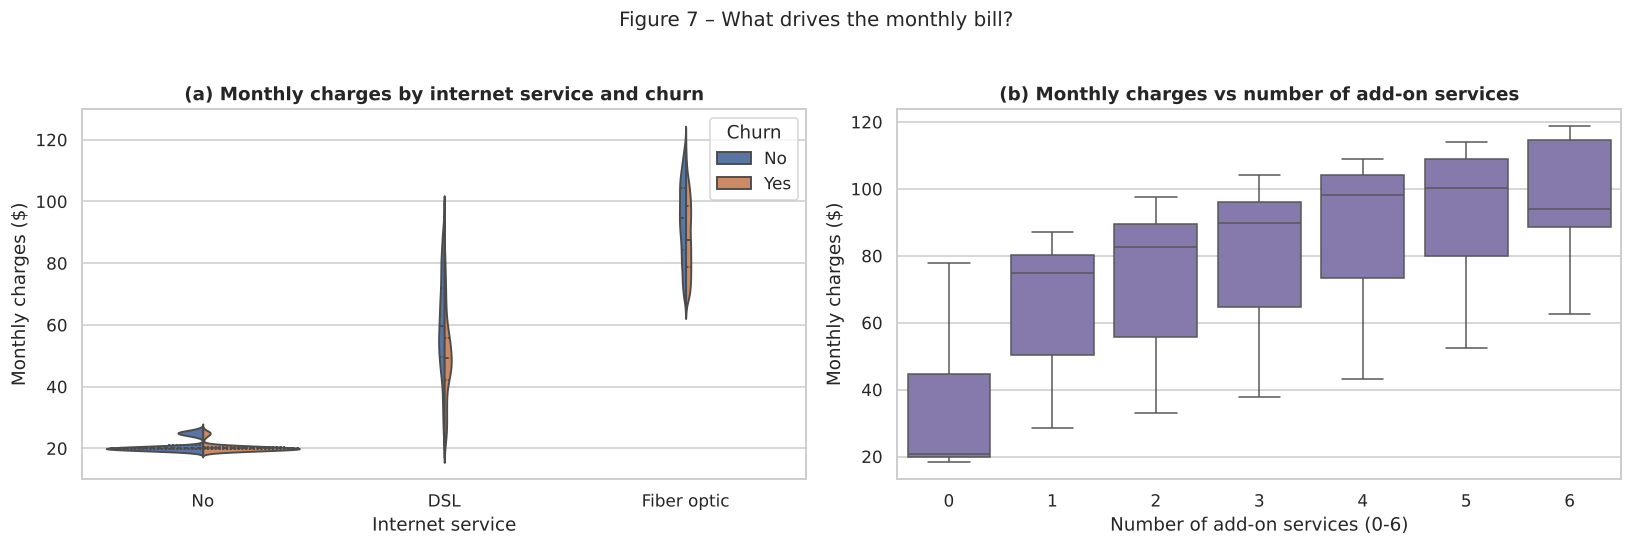

InternetService
DSL            56.15
Fiber optic    91.68
No             20.15


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.violinplot(data=df, x="InternetService", y="MonthlyCharges", hue="Churn", split=True,
               palette=CHURN_PALETTE, inner="quart", order=["No", "DSL", "Fiber optic"], ax=axes[0])
axes[0].set_title("(a) Monthly charges by internet service and churn")
axes[0].set_xlabel("Internet service")
axes[0].set_ylabel("Monthly charges ($)")

sns.boxplot(data=df, x="NumAddOnServices", y="MonthlyCharges", color="#8172B3", ax=axes[1])
axes[1].set_title("(b) Monthly charges vs number of add-on services")
axes[1].set_xlabel("Number of add-on services (0-6)")
axes[1].set_ylabel("Monthly charges ($)")

plt.suptitle("Figure 7 – What drives the monthly bill?", y=1.03, fontsize=13)
plt.tight_layout()
save_fig("fig07_pricing")
plt.show()

print(df.groupby("InternetService")["MonthlyCharges"].median().round(2).to_string())

**Insights**
* `MonthlyCharges` is almost completely determined by the **service bundle**: no internet ≈ \$20, DSL ≈ \$55–60,
  fiber ≈ \$90+, and each extra add-on raises the bill in a step-like way. This makes `MonthlyCharges` an excellent
  **target for the regression task in Deliverable 2**, since the bundle features should explain most of its variance.
* **A Simpson's-paradox-style effect:** overall, churners pay *more* per month (Section 7.2), but **within each internet
  type churners actually pay *less*** (DSL median \$49 vs \$60; fiber \$88 vs \$95). Churners hold fewer add-ons
  (≈1.6–2.0 vs ≈2.9). The overall gap exists because churners are concentrated in the expensive **fiber** tier, not
  because high bills alone cause churn. This is important for modelling: `MonthlyCharges` on its own is a confounded
  signal, and **InternetService and add-on count should be modelled together with it**.

### 7.6 Relationship between tenure, charges and churn

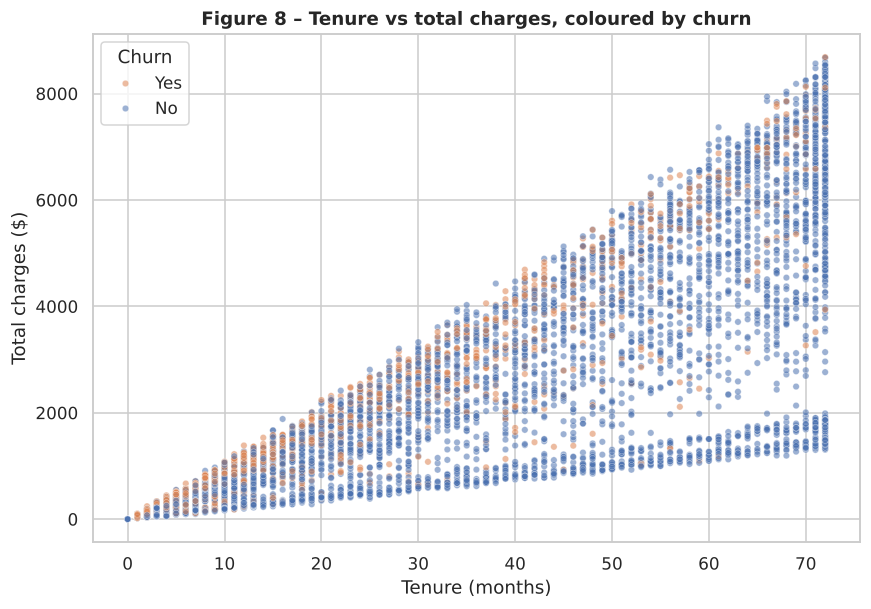

In [30]:
# Scatter plot of tenure vs lifetime charges; rows are shuffled so neither churn class is drawn entirely on top
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df.sample(frac=1, random_state=42), x="tenure", y="TotalCharges",
                hue="Churn", palette=CHURN_PALETTE, alpha=0.55, s=18, ax=ax)
ax.set_title("Figure 8 – Tenure vs total charges, coloured by churn")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Total charges ($)")
save_fig("fig08_tenure_vs_totalcharges")
plt.show()

**Insight:** points form a "fan" of straight lines radiating from the origin. Each ray corresponds to a monthly price
level, since `TotalCharges ≈ tenure × MonthlyCharges`. Churners (orange) concentrate in the **lower-left** (short tenure)
and on the **steepest rays** (high monthly price). This is visual confirmation that `TotalCharges` is a derived
feature, and that the most dangerous combination is *new + expensive*. That combination is a natural candidate for a
clustering segment in Deliverable 3.

### 7.7 Correlation analysis

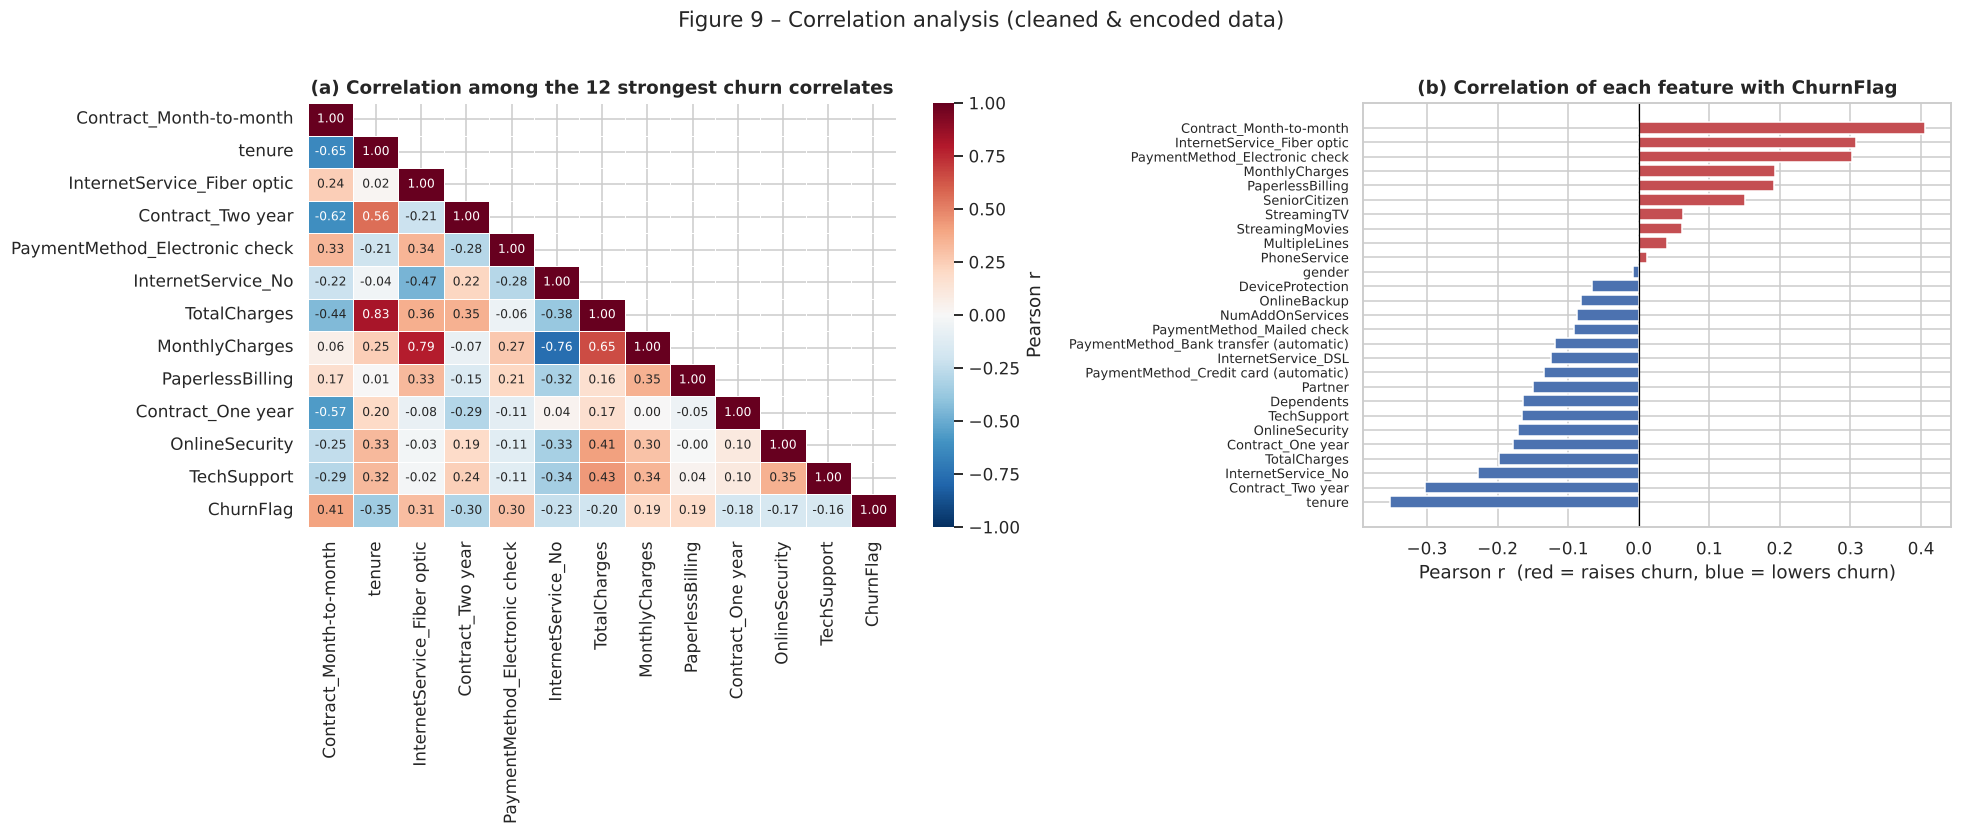

Correlation tenure vs TotalCharges        : 0.826
Correlation MonthlyCharges vs TotalCharges: 0.651


In [31]:
# Encode the cleaned data for a correlation matrix:
#   binary Yes/No -> 1/0, multi-level categoricals -> one-hot (drop_first avoids perfect collinearity)
corr_df = df.drop(columns=["customerID", "Churn", "TenureGroup"]).copy()
for c in corr_df.columns:
    if set(corr_df[c].unique()) <= {"Yes", "No"}:
        corr_df[c] = (corr_df[c] == "Yes").astype(int)
corr_df["gender"] = (corr_df["gender"] == "Male").astype(int)
corr_df = pd.get_dummies(corr_df, columns=["InternetService", "Contract", "PaymentMethod"],
                         drop_first=False, dtype=int)

corr = corr_df.corr()

# (a) Heat map of the numeric core + strongest churn correlates
target_corr = corr["ChurnFlag"].drop("ChurnFlag").sort_values()
top = list(target_corr.abs().sort_values(ascending=False).head(12).index) + ["ChurnFlag"]
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.25, 1]})
mask = np.triu(np.ones((len(top), len(top)), dtype=bool), k=1)
sns.heatmap(corr.loc[top, top], mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8}, ax=axes[0],
            cbar_kws={"label": "Pearson r"})
axes[0].set_title("(a) Correlation among the 12 strongest churn correlates")

# (b) Every feature's correlation with churn
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in target_corr.values]
axes[1].barh(target_corr.index, target_corr.values, color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("(b) Correlation of each feature with ChurnFlag")
axes[1].set_xlabel("Pearson r  (red = raises churn, blue = lowers churn)")
axes[1].tick_params(axis="y", labelsize=8.5)

plt.suptitle("Figure 9 – Correlation analysis (cleaned & encoded data)", y=1.01, fontsize=14)
plt.tight_layout()
save_fig("fig09_correlation")
plt.show()

print("Correlation tenure vs TotalCharges        :", round(corr.loc["tenure", "TotalCharges"], 3))
print("Correlation MonthlyCharges vs TotalCharges:", round(corr.loc["MonthlyCharges", "TotalCharges"], 3))

**Insights**
* **Positive churn correlates (risk factors):** month-to-month contract, fiber-optic internet, electronic-check payment,
  paperless billing, senior citizen, and higher monthly charges.
* **Negative churn correlates (protective factors):** tenure, two-year contracts, having no internet service (the cheap
  phone-only segment), online security, tech support, partner and dependents.
* **Multicollinearity warning:** `TotalCharges` correlates **r ≈ 0.83** with `tenure` and **r ≈ 0.65** with
  `MonthlyCharges`. One-hot contract and internet-service levels are also strongly inter-related. For linear and
  logistic regression we should drop `TotalCharges` (or check VIF), or use regularisation (Ridge/Lasso). Tree-based
  models are less affected.
* `gender` and `PhoneService` have near-zero correlation with churn.

## 8. Key Insights and How They Guide Future Modeling

### Summary of insights
1. **Data quality:** the raw data *appears* complete, but hides 11 blank `TotalCharges` values, a text-typed numeric column,
   inconsistent binary coding, and redundant category levels. All were resolved without dropping a single record.
2. **Churn is moderately imbalanced:** 26.5% Yes vs 73.5% No.
3. **Commitment drives retention:** contract type (43% → 11% → 3% churn) and tenure (47% in year 1 → 10% after year 4)
   are the strongest signals.
4. **Premium fiber customers are at risk:** fiber optic customers churn at 42% and pay the highest bills. Within a
   service tier, however, churners have *fewer* add-ons and *lower* bills, so the risk is tied to the fiber product
   and a thin service bundle rather than simply to price.
5. **Payment friction matters:** electronic-check users churn at 45%, compared with 15–17% for automatic payments.
6. **Protective services matter:** lacking TechSupport/OnlineSecurity roughly doubles churn (~31% vs ~15%).
7. **Weak features:** gender, PhoneService, and streaming add-ons carry little or no signal.
8. **Redundancy:** `TotalCharges` ≈ `tenure` × `MonthlyCharges` (r = 0.83 with tenure), which raises multicollinearity concerns.


## 9. Conclusion

The IBM Telco Customer Churn dataset (7,043 customers, 21 attributes) was loaded with Pandas, inspected, cleaned, and
explored. Cleaning resolved hidden missing values, a text-typed numeric column, inconsistent binary encoding, and
redundant category levels **without losing a single record**. Duplicate and noise checks confirmed that no further
records needed removal. The EDA showed that **contract type, tenure, internet service type, payment method, and
protective add-ons** are the main churn drivers, while gender and phone service carry almost no signal. These findings
set up the next steps: regression on `MonthlyCharges`, churn classification with imbalance-aware metrics,
customer segmentation by clustering, and association rules on the categorical service data.

